# 03 — Entraînement : Pipeline Spark ML (sans fuite de données)

Entraînement sur `train` (steps 1–520), tous les choix sur `validation` (steps 521–631).
Le test n'est pas utilisé ici.

**Variables du modèle principal**, toutes connues au moment de la demande :

| Variable | Pourquoi |
|---|---|
| `amount` (en log) | montant demandé |
| `type` | type de transaction |
| heure tirée de `step` | moment de la demande |
| `oldbalanceDest` | solde du destinataire **avant** la transaction (l'opérateur gère les deux comptes) |

**Exclues** : soldes **après** transaction (`newbalanceOrig`, `newbalanceDest`, et les écarts calculés avec),
soldes de l'émetteur (connus au moment de la demande, mais dans PaySim ils encodent la règle du simulateur : le compte du fraudeur est vidé exactement), identifiants `nameOrig` / `nameDest`, `isFlaggedFraud`.

Étapes :
1. Poids de classe
2. Pipeline
3. Comparaison des modèles et des jeux de variables
4. Effet du poids des fraudes
5. Hyperparamètres (`ParamGridBuilder`, évalués sur la validation temporelle)
6. Choix du seuil
7. Sauvegarde

In [1]:
from pyspark.sql import SparkSession
from pyspark.sql import functions as F

spark = (SparkSession.builder
         .appName("fraude-03-entrainement")
         .master("spark://spark-master:7077")
         .config("spark.driver.host", "spark-master")
         .config("spark.driver.memory", "2g")
         .config("spark.executor.memory", "2g")
         .config("spark.sql.shuffle.partitions", "18")
         .config("spark.sql.session.timeZone", "UTC")
         .config("spark.eventLog.enabled", "true")
         .config("spark.eventLog.dir", "file:///tmp/spark-events")
         .getOrCreate())

DATA = "/opt/spark-data"
spark

Using Spark's default log4j profile: org/apache/spark/log4j2-defaults.properties
Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).
26/11/24 14:56:57 WARN NativeCodeLoader: Unable to load native-hadoop library for your platform... using builtin-java classes where applicable


In [2]:
from pyspark.ml import Pipeline
from pyspark.ml.feature import Imputer, SQLTransformer, StringIndexer, OneHotEncoder, VectorAssembler, StandardScaler
from pyspark.ml.classification import LogisticRegression, RandomForestClassifier, GBTClassifier
from pyspark.ml.evaluation import BinaryClassificationEvaluator
from pyspark.ml.tuning import ParamGridBuilder
from pyspark.ml.functions import vector_to_array
import pandas as pd
import matplotlib.pyplot as plt

train = spark.read.parquet(DATA + "/ml/train.parquet")
validation = spark.read.parquet(DATA + "/ml/validation.parquet")

## 1. Poids de classe

Formule « balanced » : `poids = total / (2 × effectif de la classe)`, calculée sur l'entraînement.
On l'exprime ensuite comme un rapport : une transaction normale vaut 1, une fraude vaut `rapport`.

In [3]:
nb_total = train.count()
nb_fraudes = train.filter("label = 1").count()
nb_normales = nb_total - nb_fraudes

rapport = nb_normales / nb_fraudes
print("Entraînement :", nb_total, "lignes,", nb_fraudes, "fraudes")
print("Rapport balanced (poids d'une fraude) :", round(rapport, 1))


def avec_poids(donnees, poids_fraude):
    return donnees.withColumn("weight", F.when(F.col("label") == 1, float(poids_fraude)).otherwise(1.0))


train.cache()
validation.cache()
print("Validation :", validation.count(), "lignes,", validation.filter("label = 1").count(), "fraudes")

Entraînement : 6015446 lignes, 5714 fraudes
Rapport balanced (poids d'une fraude) : 1051.8


Validation : 189018 lignes, 1168 fraudes


6 015 446 lignes et 5 714 fraudes : une fraude pour environ 1 052 transactions normales. Le poids balanced donne donc 1 051,8 à chaque fraude. La validation contient 189 018 lignes et 1 168 fraudes.

## 2. Le Pipeline

| Étage | Type | Rôle |
|---|---|---|
| `Imputer` | Estimator | médiane à la place des montants et soldes manquants (calculée sur l'entraînement) |
| `SQLTransformer` | Transformer | crée `heure` (depuis `step`) et `logAmount` |
| `StringIndexer` | Estimator | `type` → indice |
| `OneHotEncoder` | Estimator | indice → vecteur 0/1 |
| `VectorAssembler` | Transformer | rassemble les features dans **une** colonne vecteur (obligatoire pour Spark ML) |
| `StandardScaler` | Estimator | met les features à la même échelle |
| Modèle | Estimator | LR / RF / GBT, avec `weightCol="weight"` |

Trois jeux de variables :
- `sans_solde` : montant, heure, type ;
- `principal` : + `oldbalanceDest` (**modèle retenu**) ;
- `avec_raccourci` : + `oldbalanceOrg`, seulement pour **mesurer** l'effet du raccourci du simulateur.

In [4]:
imputation = Imputer(inputCols=["amount", "oldbalanceDest", "oldbalanceOrg"],
                     outputCols=["amount", "oldbalanceDest", "oldbalanceOrg"],
                     strategy="median")

creation_features = SQLTransformer(statement="""
    SELECT *,
           CAST((step - 1) % 24 AS DOUBLE) AS heure,
           LOG1P(amount)                   AS logAmount
    FROM __THIS__
""")

jeux = {
    "sans_solde": ["logAmount", "heure", "typeVec"],
    "principal": ["logAmount", "heure", "typeVec", "oldbalanceDest"],
    "avec_raccourci": ["logAmount", "heure", "typeVec", "oldbalanceDest", "oldbalanceOrg"],
}


def creer_pipeline(modele, colonnes_features):
    return Pipeline(stages=[
        imputation,
        creation_features,
        StringIndexer(inputCol="type", outputCol="typeIndex"),
        OneHotEncoder(inputCol="typeIndex", outputCol="typeVec"),
        VectorAssembler(inputCols=colonnes_features, outputCol="features_raw"),
        StandardScaler(inputCol="features_raw", outputCol="features"),
        modele,
    ])


# un modèle linéaire de référence et deux modèles à base d'arbres
def creer_modele(nom):
    if nom == "lr":
        return LogisticRegression(labelCol="label", featuresCol="features", weightCol="weight", maxIter=50)
    if nom == "rf":
        return RandomForestClassifier(labelCol="label", featuresCol="features", weightCol="weight",
                                      numTrees=50, maxDepth=8, seed=42)
    if nom == "gbt":
        return GBTClassifier(labelCol="label", featuresCol="features", weightCol="weight",
                             maxIter=30, maxDepth=5, seed=42)

**Pourquoi ces 3 modèles** : la régression logistique sert de référence simple. Random Forest et GBT sont des ensembles d'arbres, qui gèrent mieux les relations non linéaires (par exemple l'heure ou les soldes à 0). Les hyperparamètres de départ restent modestes pour que la comparaison soit rapide.

## Évaluation

- **PR-AUC** : qualité du classement, indépendante du seuil. À comparer au **hasard**, qui vaut le taux de fraude.
- **Meilleur F1** : seuil qui maximise le F1, avec la précision et le rappel à ce seuil.

In [5]:
eval_pr_auc = BinaryClassificationEvaluator(labelCol="label", metricName="areaUnderPR")
liste_seuils = [0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 0.95, 0.99]


def evaluer(predictions):
    predictions = predictions.withColumn("p_fraude", vector_to_array("probability")[1]).cache()

    # pour chaque seuil : vrais positifs, faux positifs et faux négatifs
    lignes = []
    for s in liste_seuils:
        vp = predictions.filter((F.col("p_fraude") >= s) & (F.col("label") == 1)).count()
        fp = predictions.filter((F.col("p_fraude") >= s) & (F.col("label") == 0)).count()
        fn = predictions.filter((F.col("p_fraude") < s) & (F.col("label") == 1)).count()
        precision = vp / (vp + fp) if vp + fp > 0 else 0
        rappel = vp / (vp + fn) if vp + fn > 0 else 0
        f1 = 2 * precision * rappel / (precision + rappel) if precision + rappel > 0 else 0
        lignes.append({"seuil": s, "precision": precision, "rappel": rappel, "f1": f1})
    table = pd.DataFrame(lignes)

    # le meilleur seuil est celui qui donne le plus grand F1
    meilleur = table.sort_values("f1", ascending=False).iloc[0].to_dict()
    meilleur["pr_auc"] = eval_pr_auc.evaluate(predictions)
    return meilleur, table


hasard = validation.filter("label = 1").count() / validation.count()
print("PR-AUC du hasard sur la validation (taux de fraude) :", round(hasard, 4))

PR-AUC du hasard sur la validation (taux de fraude) : 0.0062


Un modèle qui répond au hasard obtient une PR-AUC d'environ 0,006 sur la validation. C'est la référence pour juger les scores suivants.

## 3. Comparaison des modèles et des jeux de variables

Tous les modèles avec le poids « balanced ». Entraînement sur `train`, score sur `validation`.

In [6]:
resultats = []
train_pondere = avec_poids(train, rapport)

for nom_jeu, colonnes in jeux.items():
    for nom_modele in ["lr", "rf", "gbt"]:
        ajuste = creer_pipeline(creer_modele(nom_modele), colonnes).fit(train_pondere)
        scores, _ = evaluer(ajuste.transform(validation))
        scores["modele"] = nom_modele
        scores["features"] = nom_jeu
        resultats.append(scores)
        print(nom_jeu, nom_modele, "| PR-AUC", round(scores["pr_auc"], 4), "| meilleur F1", round(scores["f1"], 4))

resultats = pd.DataFrame(resultats)[["features", "modele", "pr_auc", "seuil", "precision", "rappel", "f1"]]
resultats.round(4)

26/11/24 14:57:20 WARN SparkStringUtils: Truncated the string representation of a plan since it was too large. This behavior can be adjusted by setting 'spark.sql.debug.maxToStringFields'.
netlib-blas: JNI_OnLoad: dlopen(libblas.so.3) failed: libblas.so.3: cannot open shared object file: No such file or directory
                                                                                

sans_solde lr | PR-AUC 0.1011 | meilleur F1 0.1505


sans_solde rf | PR-AUC 0.3399 | meilleur F1 0.4091


sans_solde gbt | PR-AUC 0.3741 | meilleur F1 0.3955


principal lr | PR-AUC 0.1564 | meilleur F1 0.2067


principal rf | PR-AUC 0.4603 | meilleur F1 0.3989


principal gbt | PR-AUC 0.5263 | meilleur F1 0.5092


avec_raccourci lr | PR-AUC 0.4962 | meilleur F1 0.4141


avec_raccourci rf | PR-AUC 0.8286 | meilleur F1 0.776


avec_raccourci gbt | PR-AUC 0.6864 | meilleur F1 0.7647


,features,modele,pr_auc,seuil,precision,rappel,f1
0,sans_solde,lr,0.1011,0.90,0.1088,0.2440,0.1505
1,sans_solde,rf,0.3399,0.90,0.3712,0.4555,0.4091
2,sans_solde,gbt,0.3741,0.95,0.3632,0.4341,0.3955
3,principal,lr,0.1564,0.90,0.1654,0.2757,0.2067
4,principal,rf,0.4603,0.95,0.3581,0.4503,0.3989
5,principal,gbt,0.5263,0.95,0.5322,0.4880,0.5092
6,avec_raccourci,lr,0.4962,0.99,0.3785,0.4572,0.4141
7,avec_raccourci,rf,0.8286,0.90,0.7500,0.8039,0.7760
8,avec_raccourci,gbt,0.6864,0.95,0.7573,0.7723,0.7647


| Jeu de variables | Meilleur modèle | PR-AUC |
|---|---|---|
| sans_solde | GBT | 0,3741 |
| principal (+ `oldbalanceDest`) | GBT | 0,5263 |
| avec_raccourci (+ `oldbalanceOrg`) | RF | 0,8286 |

- `oldbalanceDest` apporte un vrai gain (+0,15) sans fuite.
- `oldbalanceOrg` ajoute encore +0,30 : c'est l'effet du raccourci du simulateur. Ce score n'est pas réaliste.
- La régression logistique reste faible (0,10 à 0,50) : la fraude dépend de l'heure et des soldes de façon non linéaire, ce qu'un modèle linéaire capte mal.

**Décision** : on garde le jeu `principal` et son meilleur modèle, le GBT.

Le jeu `avec_raccourci` sert seulement à mesurer l'écart : il n'est pas retenu.
On garde le meilleur modèle du jeu `principal`.

In [7]:
NOM_MODELE = resultats[resultats["features"] == "principal"].sort_values("pr_auc", ascending=False).iloc[0]["modele"]
FEATURES = jeux["principal"]
print("Modèle retenu :", NOM_MODELE)

Modèle retenu : gbt


## 4. Effet du poids des fraudes

Une transaction normale vaut 1. On teste une fraude à 1 (aucune pondération), 10, et le rapport balanced.

In [8]:
resultats_poids = []

for poids in [1, 10, rapport]:
    ajuste = creer_pipeline(creer_modele(NOM_MODELE), FEATURES).fit(avec_poids(train, poids))
    scores, _ = evaluer(ajuste.transform(validation))
    scores["poids_fraude"] = round(poids, 1)
    resultats_poids.append(scores)
    print("poids", round(poids, 1), "| PR-AUC", round(scores["pr_auc"], 4), "| meilleur F1", round(scores["f1"], 4))

resultats_poids = pd.DataFrame(resultats_poids)[["poids_fraude", "pr_auc", "seuil", "precision", "rappel", "f1"]]
POIDS = float(resultats_poids.sort_values("pr_auc", ascending=False).iloc[0]["poids_fraude"])
print("Poids retenu :", POIDS)
resultats_poids.round(4)

poids 1 | PR-AUC 0.5827 | meilleur F1 0.524


poids 10 | PR-AUC 0.5983 | meilleur F1 0.5565


poids 1051.8 | PR-AUC 0.5263 | meilleur F1 0.5092
Poids retenu : 10.0


,poids_fraude,pr_auc,seuil,precision,rappel,f1
0,1.0,0.5827,0.10,0.6121,0.4580,0.5240
1,10.0,0.5983,0.70,0.8263,0.4195,0.5565
2,1051.8,0.5263,0.95,0.5322,0.4880,0.5092


Le poids 10 donne la meilleure PR-AUC (0,5983). Le poids balanced (1 051,8) fait moins bien (0,5263) : un poids trop fort pousse le modèle à voir des fraudes partout, ce qui abîme le classement.

**Décision** : poids 10 pour une fraude.

## 5. Hyperparamètres

On construit la grille avec `ParamGridBuilder`. Chaque combinaison est entraînée sur `train` et évaluée
sur `validation`.

**Pourquoi pas `CrossValidator`** : il découpe les données au hasard, donc il mélangerait le passé et le futur. Ici on veut toujours apprendre sur le passé et juger sur la période suivante.

In [9]:
modele = creer_modele(NOM_MODELE)
if NOM_MODELE == "lr":
    grille = ParamGridBuilder().addGrid(modele.regParam, [0.001, 0.01, 0.1]).build()
elif NOM_MODELE == "rf":
    grille = ParamGridBuilder().addGrid(modele.numTrees, [50, 100]).addGrid(modele.maxDepth, [8, 10]).build()
else:
    grille = ParamGridBuilder().addGrid(modele.maxIter, [30, 60]).addGrid(modele.maxDepth, [5, 6]).build()

pipeline = creer_pipeline(modele, FEATURES)
train_final = avec_poids(train, POIDS)

meilleur_score = -1
for parametres in grille:
    ajuste = pipeline.fit(train_final, parametres)    # les paramètres de la grille remplacent ceux du modèle
    scores, _ = evaluer(ajuste.transform(validation))
    print(round(scores["pr_auc"], 4), {p.name: v for p, v in parametres.items()})
    if scores["pr_auc"] > meilleur_score:
        meilleur_score = scores["pr_auc"]
        meilleur_modele = ajuste

print("Meilleure PR-AUC en validation :", round(meilleur_score, 4))

0.5983 {'maxIter': 30, 'maxDepth': 5}


0.5993 {'maxIter': 30, 'maxDepth': 6}


0.6028 {'maxIter': 60, 'maxDepth': 5}


0.6018 {'maxIter': 60, 'maxDepth': 6}
Meilleure PR-AUC en validation : 0.6028


Les 4 combinaisons sont entre 0,5983 et 0,6028 : le réglage change très peu. La meilleure est 60 itérations, profondeur 5. Pour aller plus loin, il faudrait de nouvelles variables plutôt qu'un autre réglage.

## 6. Choix du seuil (sur la validation)
Par défaut, Spark prédit « fraude » si la probabilité dépasse 0,5. On teste les seuils de 0,1 à 0,9, plus 0,95 et 0,99 pour vérifier le haut de l'échelle, et on garde celui qui maximise le F1.

In [10]:
scores, seuils = evaluer(meilleur_modele.transform(validation))
meilleur_seuil = scores["seuil"]
print("Seuil retenu (meilleur F1) :", meilleur_seuil)
seuils.round(4)

Seuil retenu (meilleur F1) : 0.7


,seuil,precision,rappel,f1
0,0.10,0.2719,0.8022,0.4062
1,0.20,0.3645,0.6918,0.4774
2,0.30,0.5000,0.5933,0.5427
3,0.40,0.5747,0.5300,0.5514
4,0.50,0.6346,0.4863,0.5507
5,0.60,0.6523,0.4675,0.5446
6,0.70,0.7885,0.4341,0.5599
7,0.80,0.8843,0.3664,0.5182
8,0.90,0.9192,0.3116,0.4655
9,0.95,0.9587,0.1986,0.3291


Le meilleur F1 est à 0,7 (0,5599) : 79 % des alertes sont de vraies fraudes, et 43 % des fraudes sont détectées. Au-dessus de 0,7, la précision monte mais le rappel chute (à 0,99, presque rien n'est détecté).

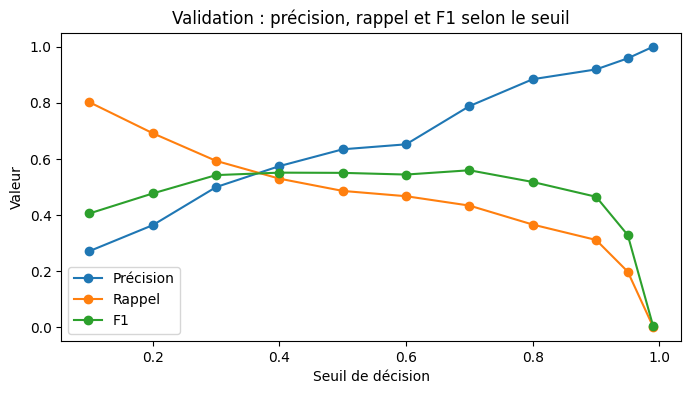

In [11]:
plt.figure(figsize=(8, 4))
plt.plot(seuils["seuil"], seuils["precision"], marker="o", label="Précision")
plt.plot(seuils["seuil"], seuils["rappel"], marker="o", label="Rappel")
plt.plot(seuils["seuil"], seuils["f1"], marker="o", label="F1")
plt.xlabel("Seuil de décision")        # axe X
plt.ylabel("Valeur")                   # axe Y
plt.title("Validation : précision, rappel et F1 selon le seuil")
plt.legend()
plt.show()

Axe X : seuil de décision ; axe Y : valeur de la métrique. La précision monte avec le seuil, le rappel descend, et le F1 est le plus haut autour de 0,7.

## 7. Sauvegarde du modèle et du seuil

In [12]:
meilleur_modele.write().overwrite().save(DATA + "/modeles/modele_fraude")

with open(DATA + "/modeles/seuil.txt", "w") as f:
    f.write(str(meilleur_seuil))

print("Modèle et seuil sauvegardés dans", DATA + "/modeles")

Modèle et seuil sauvegardés dans /opt/spark-data/modeles


In [13]:
spark.stop()